Ukuran citra asli: 452 x 678


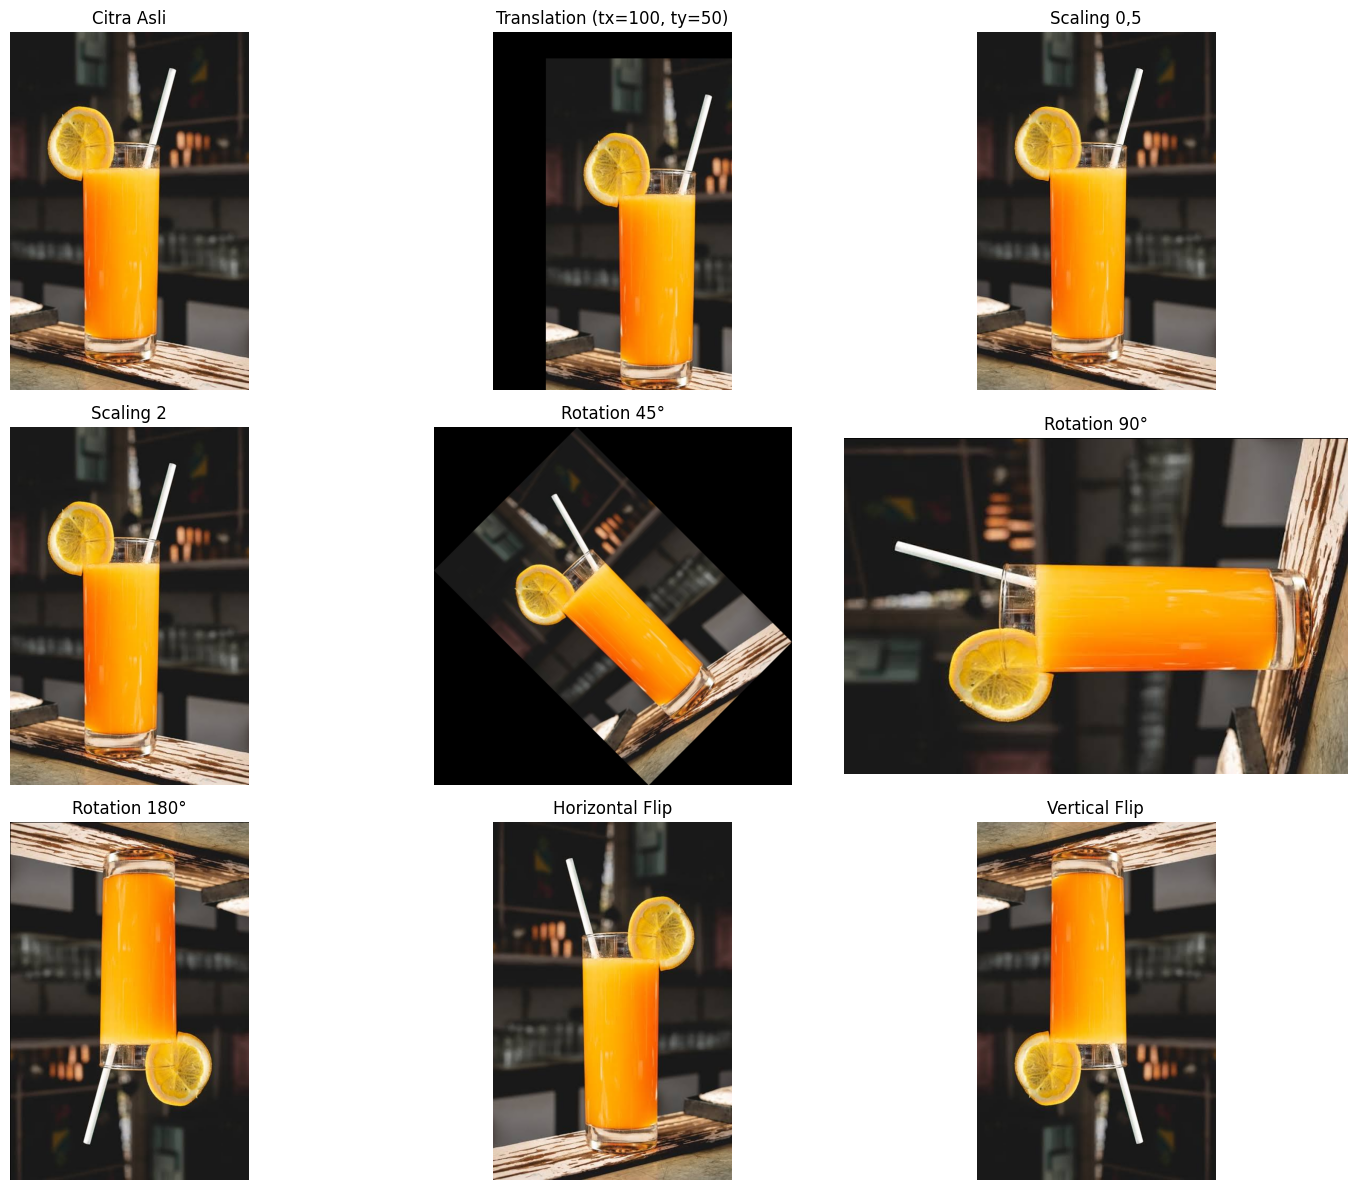

In [1]:


import cv2
import numpy as np
import matplotlib.pyplot as plt

NAMA_FILE = "gambar jus jeruk.jpg"

img = cv2.imread(NAMA_FILE)
if img is None:
    raise FileNotFoundError(f"Gambar '{NAMA_FILE}' tidak ditemukan!")

# OpenCV membaca warna BGR, Matplotlib butuh RGB
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
tinggi, lebar = img.shape[:2]
print("Ukuran citra asli:", lebar, "x", tinggi)

# ------------------------------------------------------------
# 2. TRANSLATION (menggeser citra)
#    Matriks: [[1, 0, tx], [0, 1, ty]]
#    tx = geser horizontal, ty = geser vertikal (piksel)
# ------------------------------------------------------------
tx, ty = 100, 50
M_trans = np.float32([[1, 0, tx],
                      [0, 1, ty]])
translasi = cv2.warpAffine(img, M_trans, (lebar, tinggi))

# ------------------------------------------------------------
# 3. SCALING (mengubah ukuran) faktor 0,5 dan 2
# ------------------------------------------------------------
scaling_05 = cv2.resize(img, None, fx=0.5, fy=0.5,
                        interpolation=cv2.INTER_AREA)
scaling_2 = cv2.resize(img, None, fx=2, fy=2,
                       interpolation=cv2.INTER_CUBIC)

# ------------------------------------------------------------
# 4. ROTATION (memutar) sudut 45, 90, 180 derajat
#    Diputar terhadap titik tengah citra.
#    Ukuran kanvas diperbesar agar gambar tidak terpotong.
# ------------------------------------------------------------
def rotasi(citra, sudut):
    h, w = citra.shape[:2]
    pusat = (w / 2, h / 2)
    M = cv2.getRotationMatrix2D(pusat, sudut, 1.0)

    # hitung ukuran kanvas baru
    cos, sin = abs(M[0, 0]), abs(M[0, 1])
    w_baru = int(h * sin + w * cos)
    h_baru = int(h * cos + w * sin)

    # geser agar tetap di tengah kanvas baru
    M[0, 2] += (w_baru / 2) - pusat[0]
    M[1, 2] += (h_baru / 2) - pusat[1]
    return cv2.warpAffine(citra, M, (w_baru, h_baru))

rotasi_45 = rotasi(img, 45)
rotasi_90 = rotasi(img, 90)
rotasi_180 = rotasi(img, 180)

# ------------------------------------------------------------
# 5. FLIP (mencerminkan)
#    flipCode 1 = horizontal, 0 = vertikal
# ------------------------------------------------------------
flip_h = cv2.flip(img, 1)
flip_v = cv2.flip(img, 0)

# ------------------------------------------------------------
# 6. Tampilkan citra asli + seluruh hasil transformasi
# ------------------------------------------------------------
hasil = [
    ("Citra Asli", img),
    (f"Translation (tx={tx}, ty={ty})", translasi),
    ("Scaling 0,5", scaling_05),
    ("Scaling 2", scaling_2),
    ("Rotation 45°", rotasi_45),
    ("Rotation 90°", rotasi_90),
    ("Rotation 180°", rotasi_180),
    ("Horizontal Flip", flip_h),
    ("Vertical Flip", flip_v),
]

plt.figure(figsize=(15, 12))
for i, (judul, gambar) in enumerate(hasil, start=1):
    plt.subplot(3, 3, i)
    plt.imshow(gambar)
    plt.title(judul)
    plt.axis("off")

plt.tight_layout()
plt.savefig("hasil_transformasi.png", dpi=150)  # untuk lampiran laporan
plt.show()